In [4]:
# load data
import pandas as pd

df = pd.read_csv('air_quality_dataset.csv')
df

,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835
...,...,...,...,...,...,...,...,...,...,...
495,51.380025,57.573550,31.124630,19.276010,11.167098,104.071502,1.844483,397.418878,1.923525,34.323410
496,46.816837,75.372133,22.174014,18.535162,12.169426,74.802208,1.364096,392.316075,2.157281,26.321361
497,33.909351,88.097250,27.630317,15.653370,7.997326,128.105470,2.319453,378.653347,1.809489,28.964494
498,43.721651,40.847991,27.253977,19.365916,7.218154,106.053329,1.599748,389.878566,1.858964,29.976442


In [6]:
# EDA
print(f'Cek 5 data teratas \n {df.head()} \n')

print(f'Cek tipe data \n {df.dtypes} \n')

print(f'Cek missing values \n {df.isnull().sum()}')

Cek 5 data teratas 
         PM2.5        PM10         NOx        NO2        SO2        VOCs  \
0   39.967142   57.926035  116.192213  55.230299   4.531693   75.317261   
1  101.935672  150.774299   76.826826  79.051618  18.744780  145.083987   
2   70.996192  138.948796  158.731020  60.466604  14.892239  145.147338   
3   28.464728   63.643900   25.385343  15.333286   7.647429  130.022319   
4   78.265276  113.977926  105.644340  59.202337  17.696806  181.713667   

         CO         CO2       CH4  Temperature  
0  2.789606  427.674347  1.706105    31.085120  
1  1.966569  529.739619  2.492663    33.711103  
2  2.626446  499.889443  2.431165    33.778698  
3  1.779360  388.283712  1.818563    31.565877  
4  3.240533  464.739197  2.597225    32.229835   

Cek tipe data 
 PM2.5          float64
PM10           float64
NOx            float64
NO2            float64
SO2            float64
VOCs           float64
CO             float64
CO2            float64
CH4            float64
Temperatu

In [15]:
import pandas as pd

numerical_columns = df.select_dtypes(include='number').columns

outlier_summary = []

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

    outlier_summary.append({
        'kolom': column,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'batas_bawah': lower_bound,
        'batas_atas': upper_bound,
        'jumlah_outlier': len(outliers),
        'persen_outlier': round(len(outliers) / len(df) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df

,kolom,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_outlier,persen_outlier
0,PM2.5,36.372940,73.820566,37.447627,-19.798501,129.992007,0,0.0
1,PM10,61.118607,110.270086,49.151479,-12.608611,183.997305,0,0.0
2,NOx,35.457263,134.709240,99.251977,-113.420703,283.587206,0,0.0
3,NO2,17.448632,63.817763,46.369131,-52.105064,133.371459,0,0.0
4,SO2,5.976492,17.116673,11.140181,-10.733779,33.826944,0,0.0
5,VOCs,81.516729,140.588100,59.071371,-7.090328,229.195157,1,0.2
6,CO,1.536915,2.726020,1.189105,-0.246743,4.509678,5,1.0
7,CO2,397.399610,490.968315,93.568705,257.046553,631.321371,0,0.0
8,CH4,1.837395,2.386267,0.548872,1.014088,3.209574,3,0.6
9,Temperature,28.481974,32.614954,4.132980,22.282505,38.814424,4,0.8


In [12]:
# separation x and y
x = df.drop(columns = ['CO'])
y = df['CO']

In [13]:
# split data
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42
)

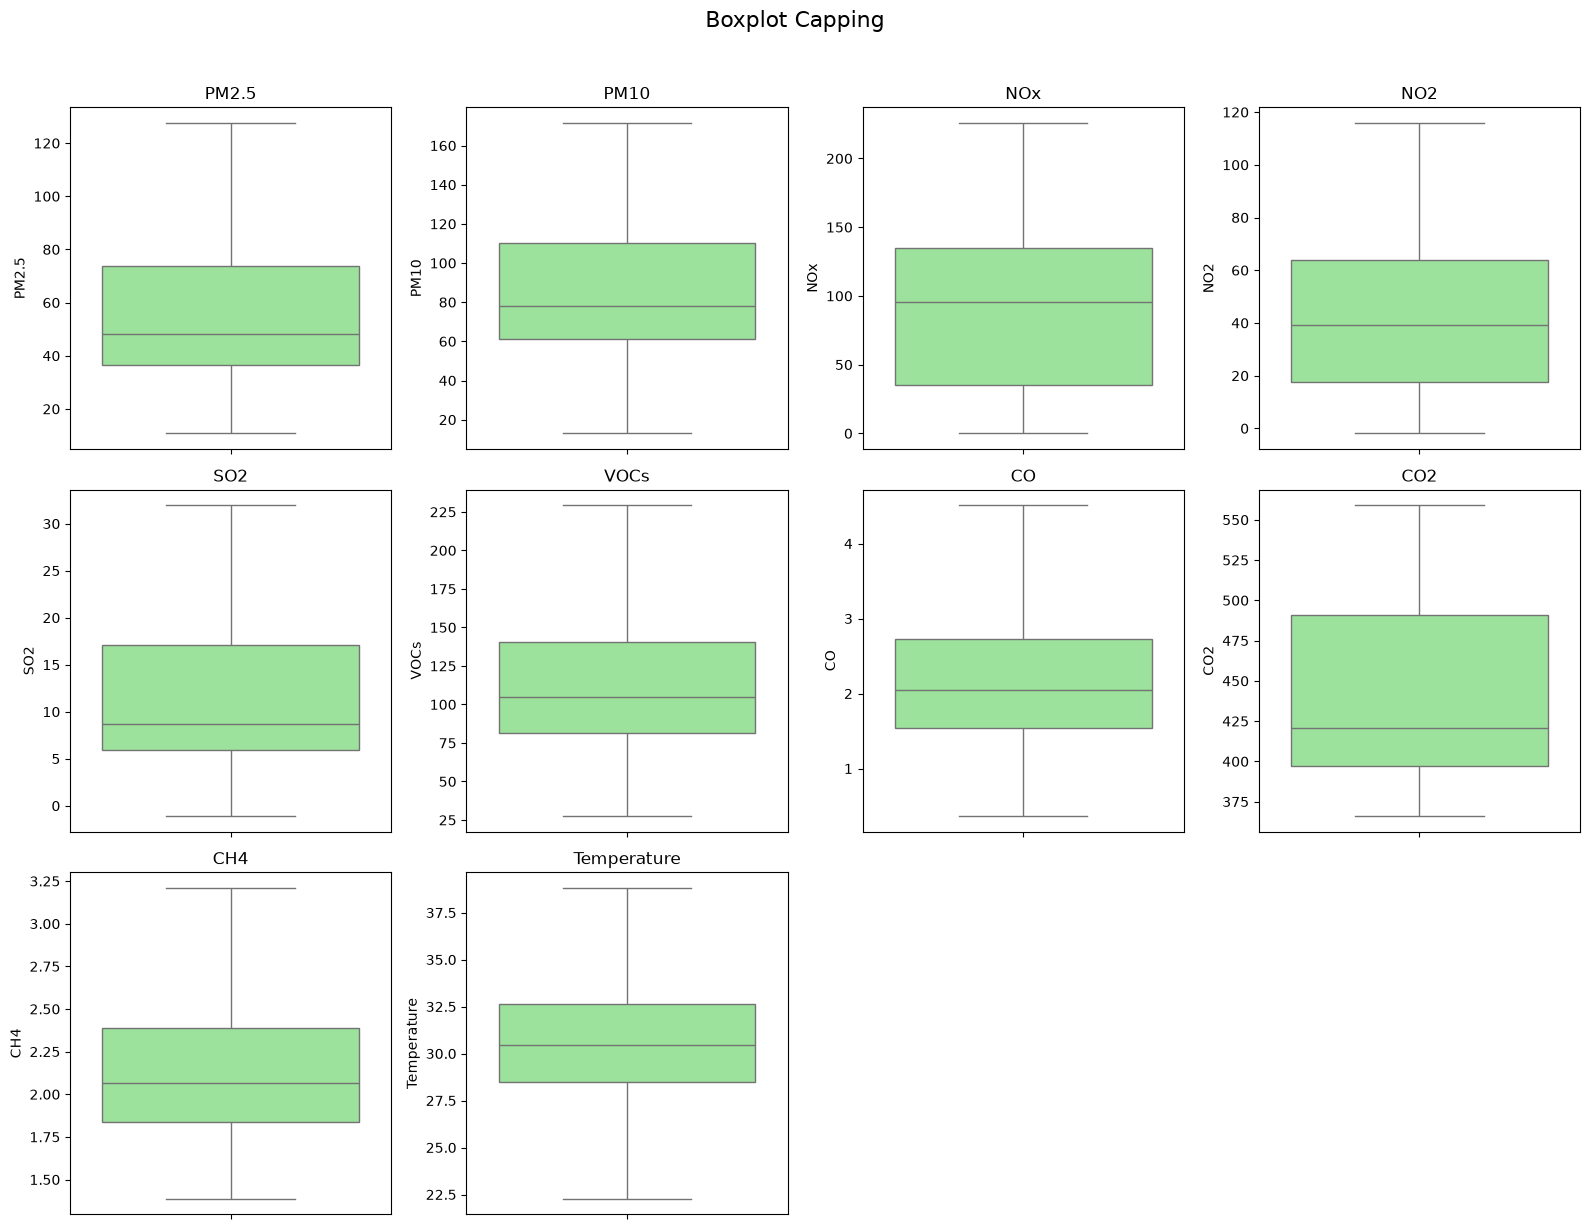

In [21]:
#handle outlier
import math
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(4 * n_cols, 4 * n_rows))
for i, column in enumerate(numerical_columns):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.boxplot(y=df_capped[column], color='lightgreen')
    plt.title(column)
plt.suptitle('Boxplot Capping', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# encoding
